# Modelos de Clasificación — Ejercicios 1.1 a 4.2
**Ingeniería del Conocimiento (ISO56B) — UNCP, 2026-II**

Notebook completo con los 12 ejercicios del material de refuerzo.

**ESTUDIANTE:** Espinoza Inga Deysi

| Nivel | Ejercicios |
|---|---|
| 1 Básico | 1.1 Exploración Wine · 1.2 Train/Test split · 1.3 Estandarización |
| 2 Intermedio | 2.1 Dígitos · 2.2 K óptimo en KNN · 2.3 Kernels SVM · 2.4 Profundidad del árbol |
| 3 Avanzado | 3.1 Pipeline + CV · 3.2 GridSearch SVM · 3.3 Clases desbalanceadas · 3.4 Heart Disease |
| 4 Desafío | 4.1 Comparación multi-dataset · 4.2 Features irrelevantes |



In [17]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RS = 42  # semilla para reproducibilidad

from sklearn.datasets import (load_wine, load_iris, load_breast_cancer, load_digits,
                              make_moons, make_circles, make_classification, fetch_openml)
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate, cross_val_predict,
                                     StratifiedKFold, GridSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score, make_scorer,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, roc_auc_score)
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.feature_selection import f_classif, SelectKBest

---
# Nivel 1: Básico
## Ejercicio 1.1 — Exploración del dataset Wine
`load_wine()`: 178 muestras, 13 features, 3 clases.

In [18]:
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["target"] = wine.target
df["clase"] = df["target"].map(dict(enumerate(wine.target_names)))
print("Dimensiones:", df.shape)
print("Features:", list(wine.feature_names))
print("Valores faltantes:", df.isna().sum().sum())
df.head()

Dimensiones: (178, 15)
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Valores faltantes: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


clase
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


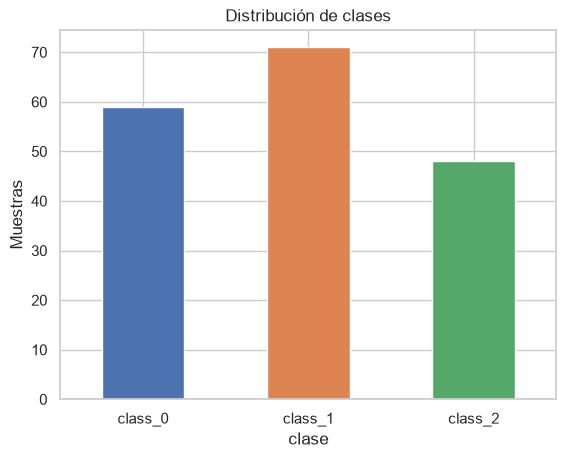

In [19]:
conteo = df["clase"].value_counts().sort_index()
print(conteo)
ax = conteo.plot(kind="bar", color=["#4C72B0", "#DD8452", "#55A868"], rot=0)
ax.set_title("Distribución de clases"); ax.set_ylabel("Muestras")
plt.show()

In [20]:
# Estadísticas descriptivas por clase
display(df.groupby("clase")[wine.feature_names].mean().T.round(2))
df.groupby("clase")[wine.feature_names].describe().T.round(2)

clase,class_0,class_1,class_2
alcohol,13.74,12.28,13.15
malic_acid,2.01,1.93,3.33
ash,2.46,2.24,2.44
alcalinity_of_ash,17.04,20.24,21.42
magnesium,106.34,94.55,99.31
total_phenols,2.84,2.26,1.68
flavanoids,2.98,2.08,0.78
nonflavanoid_phenols,0.29,0.36,0.45
proanthocyanins,1.90,1.63,1.15
color_intensity,5.53,3.09,7.40


clase          class_0  class_1  class_2
alcohol count    59.00    71.00    48.00
        mean     13.74    12.28    13.15
        std       0.46     0.54     0.53
        min      12.85    11.03    12.20
        25%      13.40    11.92    12.80
...                ...      ...      ...
proline min     680.00   278.00   415.00
        25%     987.50   406.50   545.00
        50%    1095.00   495.00   627.50
        75%    1280.00   625.00   695.00
        max    1680.00   985.00   880.00

[104 rows x 3 columns]

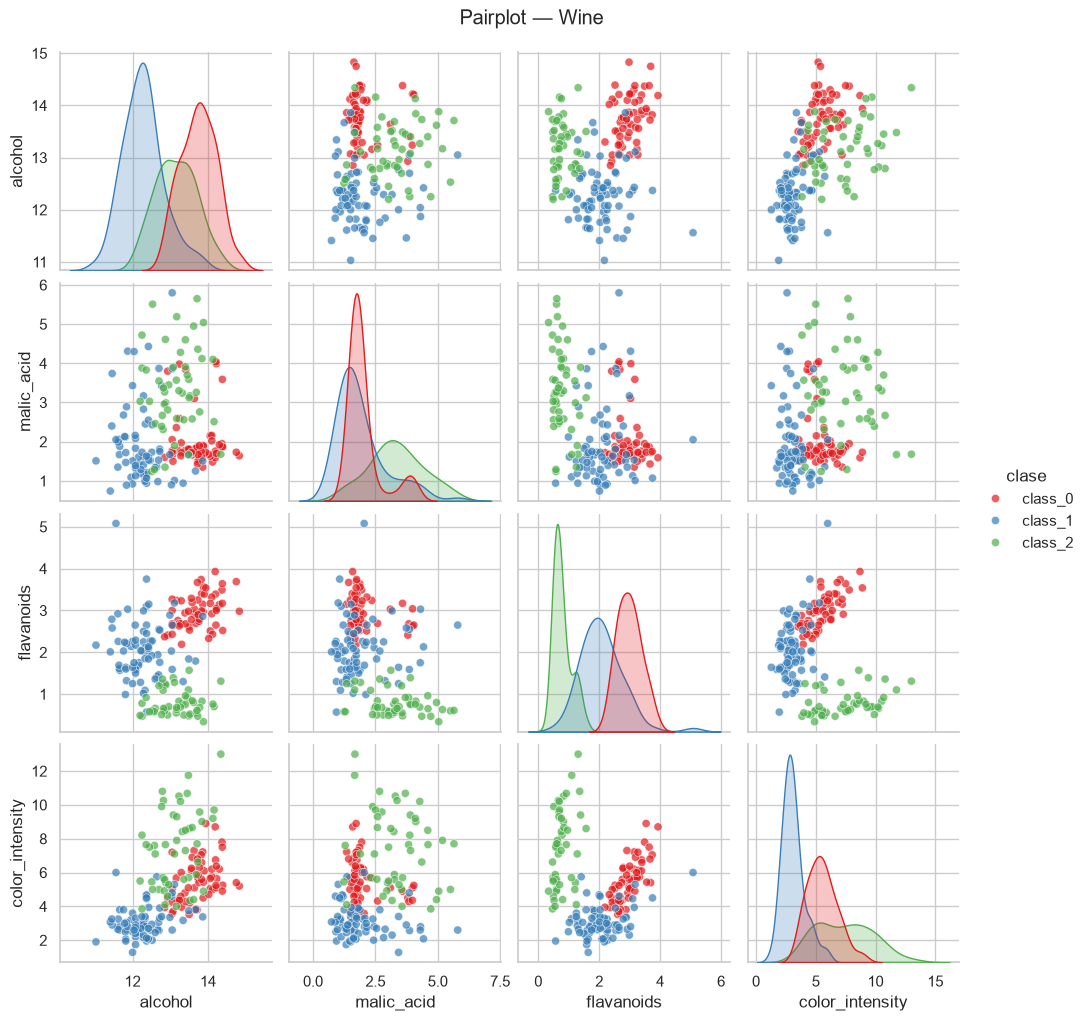

In [21]:
feats4 = ["alcohol", "malic_acid", "flavanoids", "color_intensity"]
g = sns.pairplot(df, vars=feats4, hue="clase", palette="Set1", diag_kind="kde", plot_kws={"alpha": 0.7, "s": 35})
g.figure.suptitle("Pairplot — Wine", y=1.02); plt.show()

,feature,F
0,flavanoids,233.93
1,proline,207.92
2,od280/od315_of_diluted_wines,189.97
3,alcohol,135.08
4,color_intensity,120.66
5,hue,101.32
6,total_phenols,93.73
7,malic_acid,36.94
8,alcalinity_of_ash,35.77
9,proanthocyanins,30.27


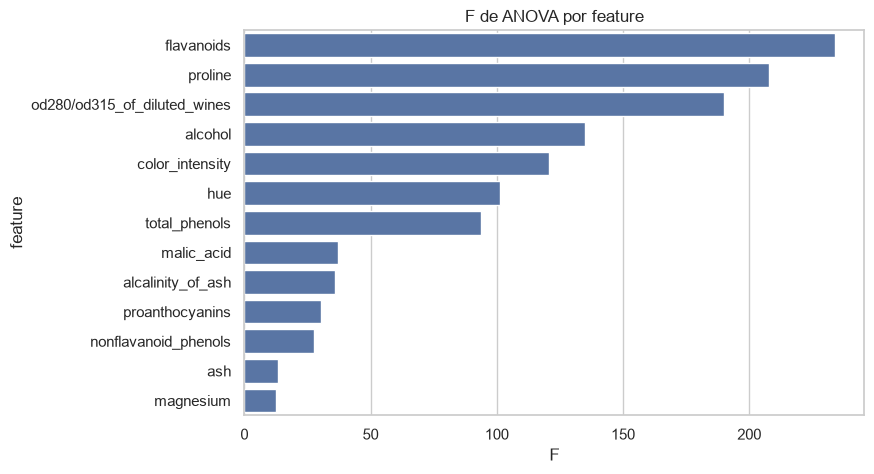

In [22]:
# Apoyo: poder discriminante de cada feature (F de ANOVA)
F, p = f_classif(wine.data, wine.target)
ranking = pd.DataFrame({"feature": wine.feature_names, "F": F}).sort_values("F", ascending=False).reset_index(drop=True)
display(ranking.round(2))
plt.figure(figsize=(8, 5)); sns.barplot(data=ranking, y="feature", x="F", color="#4C72B0"); plt.title("F de ANOVA por feature"); plt.show()

**Respuestas 1.1**

- **¿Las 3 clases se separan visualmente?** En gran medida sí: combinando `flavanoids` y `color_intensity` se forman grupos claramente distinguibles; con `alcohol` y `malic_acid` por separado hay más solapamiento.
- **¿Features más discriminantes?** Según F de ANOVA: `flavanoids`, `proline`, `od280/od315_of_diluted_wines`, `alcohol` y `color_intensity`. `malic_acid` es de las menos útiles entre las 4 pedidas.

## Ejercicio 1.2 — Train/Test split y su efecto
`load_iris()` + Regresión Logística.

In [23]:
iris = load_iris(); X, y = iris.data, iris.target

filas = []
for ts in [0.1, 0.3, 0.5]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=ts, random_state=RS)
    m = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
    filas.append({"test_size": ts, "n_train": len(Xtr), "n_test": len(Xte),
                  "acc_train": m.score(Xtr, ytr), "acc_test": m.score(Xte, yte)})
display(pd.DataFrame(filas).round(4))

filas = []
for rs in [0, 7, 42, 99]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=rs)
    m = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
    filas.append({"random_state": rs, "acc_train": m.score(Xtr, ytr), "acc_test": m.score(Xte, yte)})
res_rs = pd.DataFrame(filas)
display(res_rs.round(4))
print(f"Accuracy test: media={res_rs.acc_test.mean():.4f}  std={res_rs.acc_test.std():.4f}")

,test_size,n_train,n_test,acc_train,acc_test
0,0.1,135,15,0.9778,1.0
1,0.3,105,45,0.9619,1.0
2,0.5,75,75,0.9200,1.0


,random_state,acc_train,acc_test
0,0,0.9667,1.0000
1,7,0.9917,0.8667
2,42,0.9750,1.0000
3,99,0.9833,0.9333


Accuracy test: media=0.9500  std=0.0638


In [24]:
# Solución propuesta: validación cruzada estratificada
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
sc = cross_val_score(LogisticRegression(max_iter=1000), X, y, cv=cv)
print("Accuracy por fold:", sc.round(3)); print(f"Media={sc.mean():.4f}  std={sc.std():.4f}")

Accuracy por fold: [1.    0.967 0.933 1.    0.933]
Media=0.9667  std=0.0298


**Respuestas 1.2**

- **¿Por qué cambian los resultados con distinto `random_state`?** Cada semilla produce una partición distinta. Con pocas muestras (Iris: 150, test de 30), cada punto mal clasificado cambia la accuracy ~3 puntos; el resultado depende de qué casos "difíciles" caen en test. Además, con `test_size` grande se entrena con menos datos y con `test_size` pequeño la estimación en test es muy ruidosa.
- **Solución:** **validación cruzada** (k-fold estratificada, idealmente repetida) y reportar media ± desviación estándar, en lugar de depender de una sola partición.

## Ejercicio 1.3 — Efecto de la estandarización
`load_breast_cancer()`: KNN (K=5) y Árbol con y sin `StandardScaler`.

In [25]:
bc = load_breast_cancer()
Xtr, Xte, ytr, yte = train_test_split(bc.data, bc.target, test_size=0.3, stratify=bc.target, random_state=RS)

modelos = {"KNN (K=5)": lambda: KNeighborsClassifier(n_neighbors=5),
           "Árbol de Decisión": lambda: DecisionTreeClassifier(random_state=RS)}
filas = []
for nombre, mk in modelos.items():
    sin = mk().fit(Xtr, ytr).score(Xte, yte)
    con = make_pipeline(StandardScaler(), mk()).fit(Xtr, ytr).score(Xte, yte)
    filas.append({"Modelo": nombre, "Sin estandarizar": sin, "Con StandardScaler": con, "Diferencia": con - sin})
display(pd.DataFrame(filas).round(4))

,Modelo,Sin estandarizar,Con StandardScaler,Diferencia
0,KNN (K=5),0.9240,0.9591,0.0351
1,Árbol de Decisión,0.9181,0.9181,0.0000


**Respuestas 1.3**

- **KNN sí es afectado:** calcula distancias euclidianas; las features con escala grande (p. ej. `area`, de cientos/miles) dominan la distancia sobre las de escala pequeña. Al estandarizar, todas contribuyen en igual medida y la accuracy suele mejorar notablemente.
- **El Árbol no es afectado:** cada nodo divide por un umbral sobre **una sola feature**, y esa división es invariante a transformaciones monótonas (como el escalado). Las accuracies deben ser idénticas o casi idénticas.

---
# Nivel 2: Intermedio
## Ejercicio 2.1 — Clasificación de dígitos escritos a mano
`load_digits()`: 1797 imágenes 8×8, 10 clases.

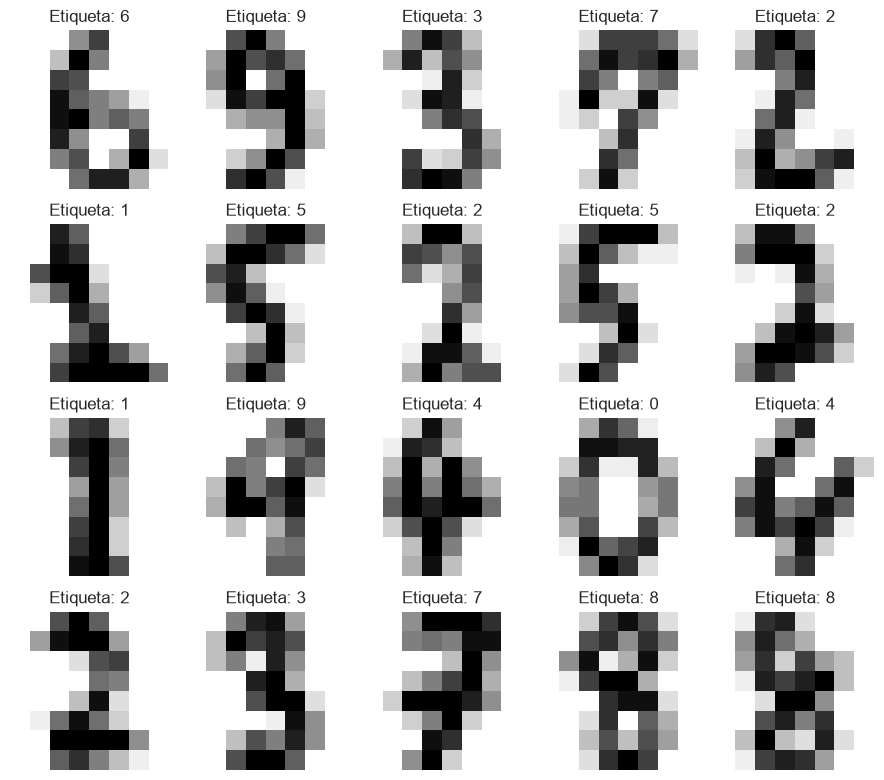

In [26]:
digits = load_digits()
rng = np.random.RandomState(RS)
idx = rng.choice(len(digits.images), 20, replace=False)
fig, axes = plt.subplots(4, 5, figsize=(9, 8))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(digits.images[i], cmap="gray_r"); ax.set_title(f"Etiqueta: {digits.target[i]}"); ax.axis("off")
plt.tight_layout(); plt.show()

===== Reg. Logística — accuracy = 0.9583
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.89      0.89      0.89        36
           2       0.97      1.00      0.99        35
           3       0.95      1.00      0.97        37
           4       0.95      1.00      0.97        36
           5       0.97      0.97      0.97        37
           6       1.00      0.97      0.99        36
           7       1.00      0.97      0.99        36
           8       0.86      0.86      0.86        35
           9       1.00      0.94      0.97        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360

===== SVM (RBF) — accuracy = 0.9917
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      1.00      0.97        36
 

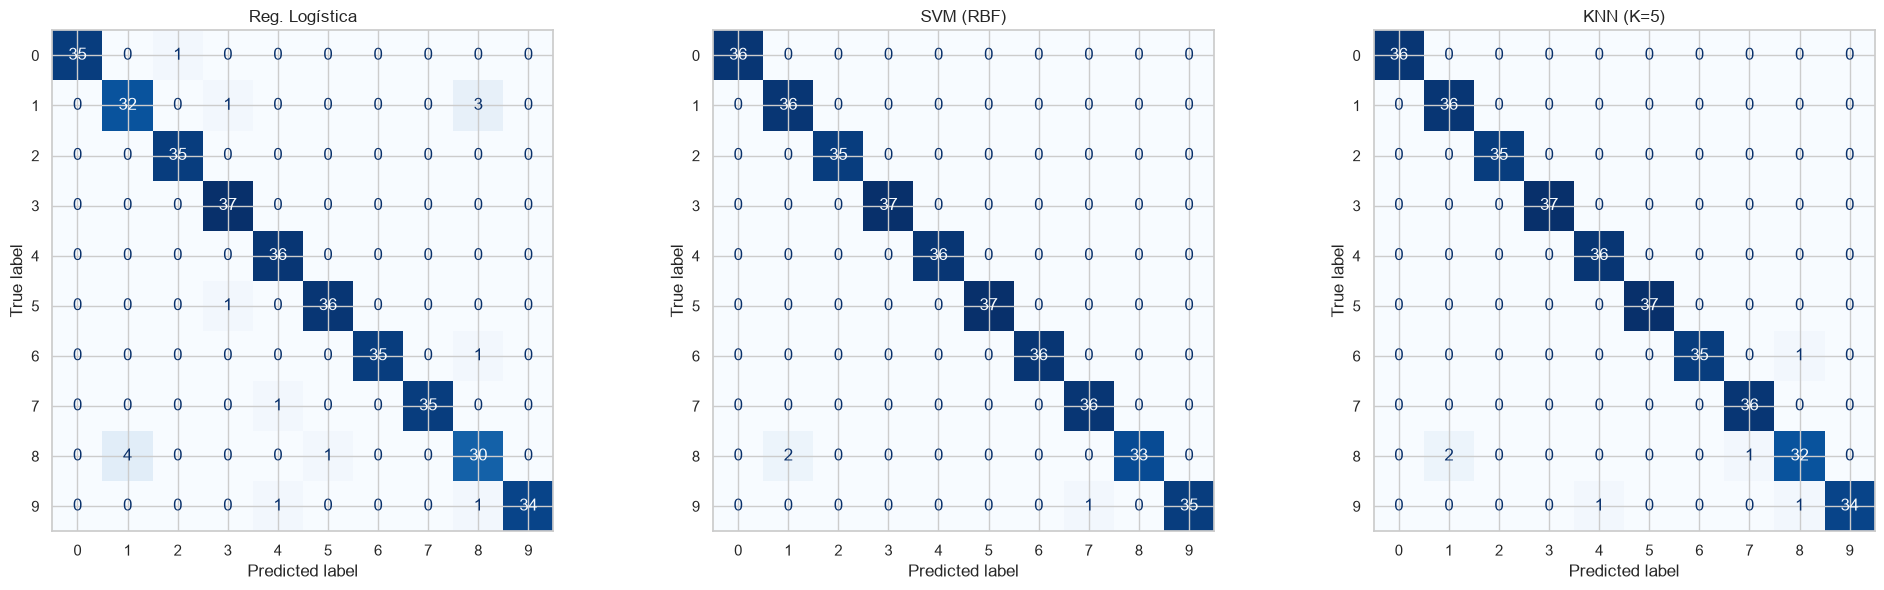

In [27]:
Xtr, Xte, ytr, yte = train_test_split(digits.data, digits.target, test_size=0.2, stratify=digits.target, random_state=RS)
modelos = {"Reg. Logística": LogisticRegression(max_iter=5000),
           "SVM (RBF)": SVC(kernel="rbf"),
           "KNN (K=5)": KNeighborsClassifier(n_neighbors=5)}
accs, preds = {}, {}
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (nombre, m) in zip(axes, modelos.items()):
    m.fit(Xtr, ytr); p = m.predict(Xte); preds[nombre] = p
    accs[nombre] = accuracy_score(yte, p)
    print(f"===== {nombre} — accuracy = {accs[nombre]:.4f}")
    print(classification_report(yte, p))
    ConfusionMatrixDisplay.from_predictions(yte, p, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nombre)
plt.tight_layout(); plt.show()

Mejor modelo: SVM (RBF)
  real 8 -> predicho 1: 2 veces
  real 9 -> predicho 7: 1 veces


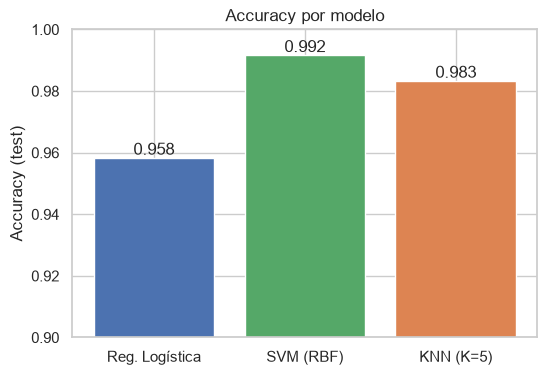

In [28]:
# Pares de dígitos más confundidos (mejor modelo)
mejor = max(accs, key=accs.get)
cm = confusion_matrix(yte, preds[mejor]); np.fill_diagonal(cm, 0)
pares = sorted([(cm[i, j], i, j) for i in range(10) for j in range(10) if cm[i, j] > 0], reverse=True)[:5]
print(f"Mejor modelo: {mejor}")
for n, i, j in pares: print(f"  real {i} -> predicho {j}: {n} veces")

plt.figure(figsize=(6, 4))
plt.bar(accs.keys(), accs.values(), color=["#4C72B0", "#55A868", "#DD8452"])
plt.ylim(0.9, 1.0); plt.ylabel("Accuracy (test)"); plt.title("Accuracy por modelo")
for i, v in enumerate(accs.values()): plt.text(i, v + 0.001, f"{v:.3f}", ha="center")
plt.show()

**Respuestas 2.1** — Los tres modelos superan el ~95 %, típicamente SVM-RBF y KNN ≈ 98–99 %. Los errores son pocos y se dan entre dígitos de trazo parecido (en la ejecución de referencia, p. ej. **8→1 y 9→7**; también son típicas **3↔8, 4↔9, 5↔9**), lo que tiene sentido visualmente: a 8×8 píxeles esas formas comparten bucles o trazos. Revisa los pares exactos que imprimió tu ejecución.

## Ejercicio 2.2 — Búsqueda del K óptimo en KNN
`load_wine()` estandarizado, K de 1 a 30.

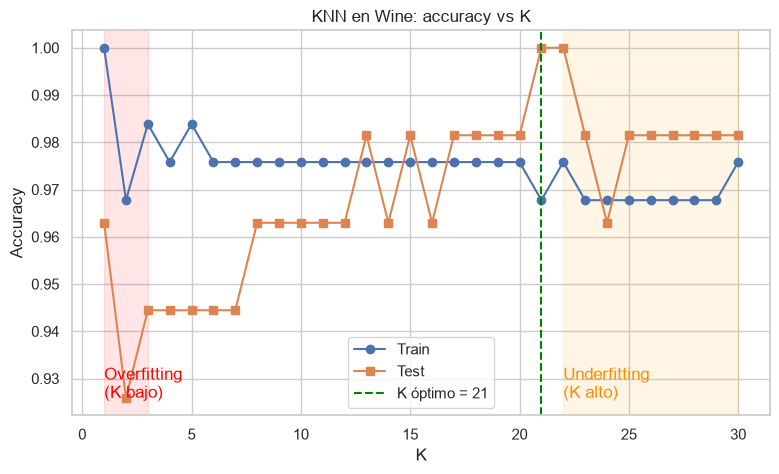

K óptimo = 21  (accuracy test = 1.0000)


In [29]:
Xtr, Xte, ytr, yte = train_test_split(wine.data, wine.target, test_size=0.3, stratify=wine.target, random_state=RS)
sc = StandardScaler().fit(Xtr)           # el scaler se ajusta SOLO con train
Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)

Ks = range(1, 31); acc_tr, acc_te = [], []
for k in Ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(Xtr_s, ytr)
    acc_tr.append(m.score(Xtr_s, ytr)); acc_te.append(m.score(Xte_s, yte))
acc_tr, acc_te = np.array(acc_tr), np.array(acc_te)
k_opt = int(np.argmax(acc_te)) + 1          # primer K con accuracy máxima

plt.figure(figsize=(9, 5))
plt.plot(Ks, acc_tr, "o-", label="Train"); plt.plot(Ks, acc_te, "s-", label="Test")
plt.axvline(k_opt, color="green", ls="--", label=f"K óptimo = {k_opt}")
plt.axvspan(1, 3, color="red", alpha=0.1); plt.text(1, acc_te.min(), "Overfitting\n(K bajo)", color="red")
plt.axvspan(22, 30, color="orange", alpha=0.1); plt.text(22, acc_te.min(), "Underfitting\n(K alto)", color="darkorange")
plt.xlabel("K"); plt.ylabel("Accuracy"); plt.title("KNN en Wine: accuracy vs K"); plt.legend(); plt.show()
print(f"K óptimo = {k_opt}  (accuracy test = {acc_te[k_opt-1]:.4f})")

In [30]:
final = KNeighborsClassifier(n_neighbors=k_opt).fit(Xtr_s, ytr)
print(classification_report(yte, final.predict(Xte_s), target_names=wine.target_names))

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      1.00      1.00        21
     class_2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



**Respuestas 2.2** — Con **K bajo** (1–3) el modelo se ajusta al ruido (accuracy de train ≈ 1, test más bajo): *overfitting*. Con **K alto** el modelo promedia demasiados vecinos y suaviza en exceso: ambas curvas bajan (*underfitting*). Nota: elegir K con el máximo en un único test es optimista; en la práctica se elige con validación cruzada (ver 3.2).

## Ejercicio 2.3 — Comparación de kernels en SVM
`make_moons(noise=0.3)` y `make_circles(noise=0.2, factor=0.5)`.

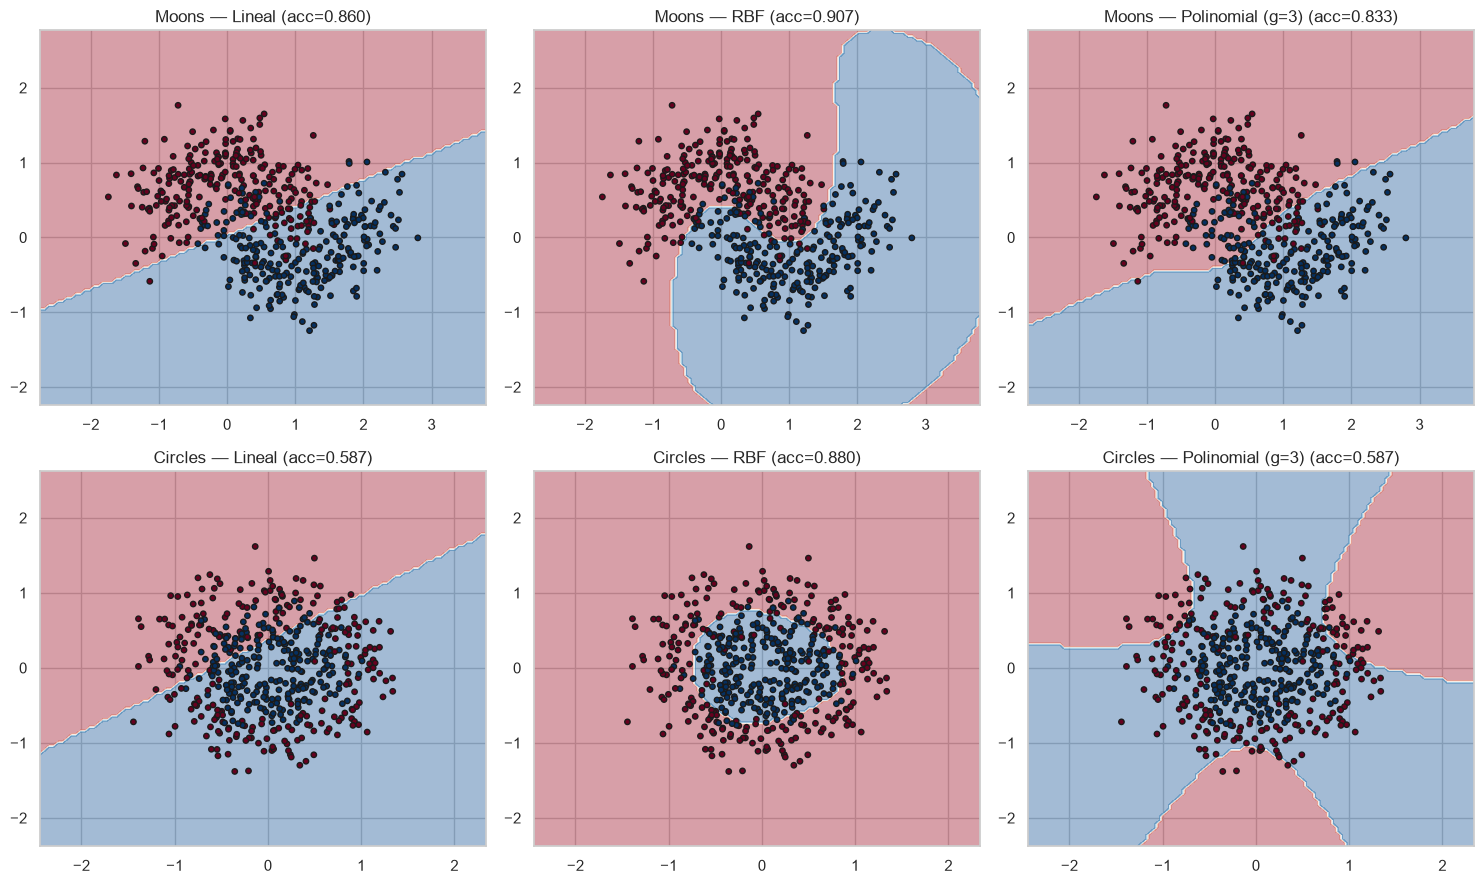

Kernel,Lineal,Polinomial (g=3),RBF
Dataset,,,
Circles,0.587,0.587,0.880
Moons,0.860,0.833,0.907


In [31]:
conjuntos = {"Moons": make_moons(n_samples=500, noise=0.3, random_state=RS),
             "Circles": make_circles(n_samples=500, noise=0.2, factor=0.5, random_state=RS)}
kernels = {"Lineal": SVC(kernel="linear"), "RBF": SVC(kernel="rbf"), "Polinomial (g=3)": SVC(kernel="poly", degree=3)}

fig, axes = plt.subplots(2, 3, figsize=(15, 9)); filas = []
for r, (dn, (X, y)) in enumerate(conjuntos.items()):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=RS)
    for cidx, (kn, k) in enumerate(kernels.items()):
        m = clone(k).fit(Xtr, ytr); acc = m.score(Xte, yte)
        filas.append({"Dataset": dn, "Kernel": kn, "Accuracy test": acc})
        ax = axes[r, cidx]
        DecisionBoundaryDisplay.from_estimator(m, X, response_method="predict", cmap="RdBu", alpha=0.4, ax=ax)
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu", edgecolors="k", s=15)
        ax.set_title(f"{dn} — {kn} (acc={acc:.3f})")
plt.tight_layout(); plt.show()
pd.DataFrame(filas).pivot(index="Dataset", columns="Kernel", values="Accuracy test").round(3)

**Respuestas 2.3** — El kernel **lineal** solo traza una frontera recta; en *moons* las dos clases son medias lunas entrelazadas, por lo que ninguna recta las separa bien (acc ≈ 0.86 en la ejecución de referencia). **RBF** es el mejor en ambas formas (≈ 0.91 en moons, ≈ 0.88 en circles) porque dibuja fronteras curvas arbitrarias. En *circles* el lineal (≈ 0.59) y el polinomial de grado 3 (≈ 0.59) fallan: una recta o una cúbica no pueden encerrar un círculo interno dentro de un anillo; el polinomial tampoco mejora al lineal en moons.

## Ejercicio 2.4 — Árbol de Decisión: efecto de la profundidad
`load_breast_cancer()`, `max_depth` de 1 a 15.

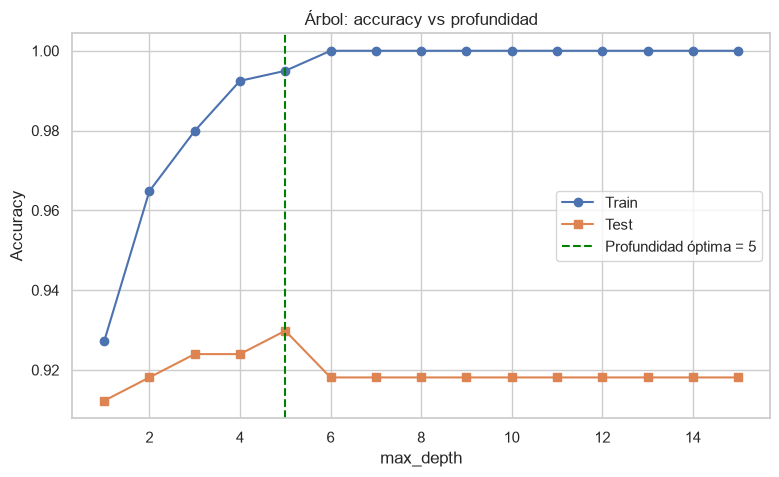

Profundidad óptima: 5 | acc test: 0.9298


In [32]:
Xtr, Xte, ytr, yte = train_test_split(bc.data, bc.target, test_size=0.3, stratify=bc.target, random_state=RS)
depths = range(1, 16); tr, te = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=RS).fit(Xtr, ytr)
    tr.append(t.score(Xtr, ytr)); te.append(t.score(Xte, yte))
d_opt = int(np.argmax(te)) + 1

plt.figure(figsize=(9, 5))
plt.plot(depths, tr, "o-", label="Train"); plt.plot(depths, te, "s-", label="Test")
plt.axvline(d_opt, color="green", ls="--", label=f"Profundidad óptima = {d_opt}")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.title("Árbol: accuracy vs profundidad"); plt.legend(); plt.show()
print("Profundidad óptima:", d_opt, "| acc test:", round(te[d_opt-1], 4))

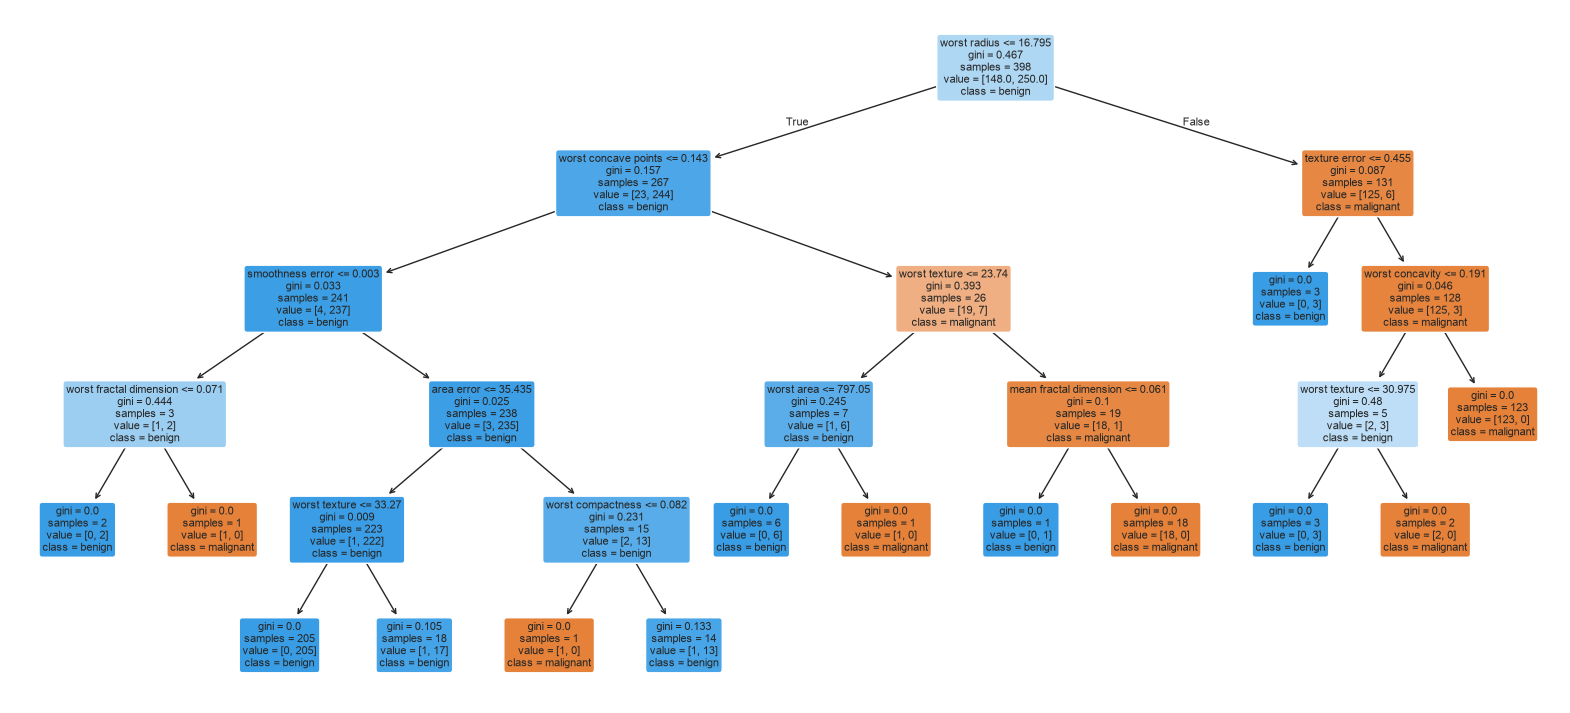

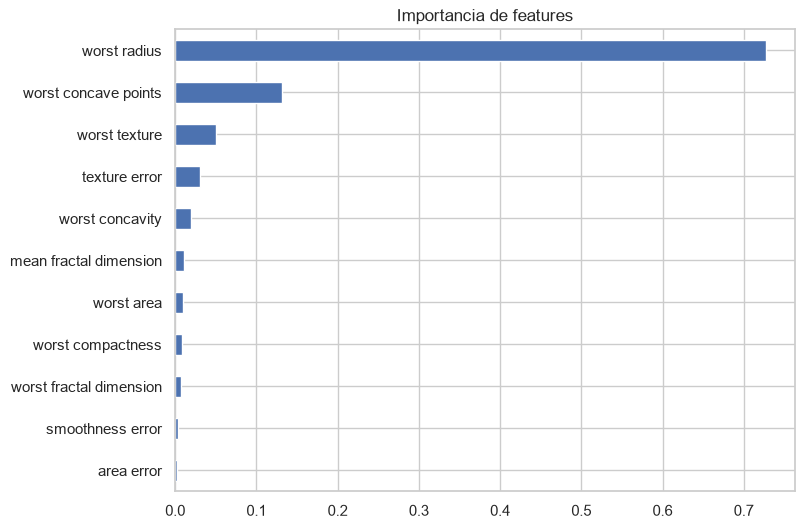

Top 5 features:
worst radius            0.7270
worst concave points    0.1314
worst texture           0.0501
texture error           0.0307
worst concavity         0.0190
dtype: float64


In [33]:
arbol = DecisionTreeClassifier(max_depth=d_opt, random_state=RS).fit(Xtr, ytr)
plt.figure(figsize=(20, 9))
plot_tree(arbol, feature_names=bc.feature_names, class_names=bc.target_names, filled=True, rounded=True, fontsize=8)
plt.show()

imp = pd.Series(arbol.feature_importances_, index=bc.feature_names).sort_values()
imp[imp > 0].plot(kind="barh", figsize=(8, 6), color="#4C72B0"); plt.title("Importancia de features"); plt.show()
print("Top 5 features:"); print(imp.sort_values(ascending=False).head(5).round(4))

**Respuestas 2.4** — Con profundidad baja el árbol no captura el patrón (*underfitting*); al aumentarla, el accuracy de **train llega a 1.0** mientras el de **test se estanca o baja**: ahí está el sobreajuste (el punto de inflexión suele estar en profundidad 3–5). En la ejecución de referencia el top 5 fue `worst radius` (con diferencia, ≈ 0.73), `worst concave points`, `worst texture`, `texture error` y `worst concavity`: dominan las medidas *worst* de tamaño y concavidad del tumor. Confirma tu top 5 con la tabla impresa.

---
# Nivel 3: Avanzado
## Ejercicio 3.1 — Pipeline completo con Cross-Validation
Wine Quality Red (UCI). Target binario: calidad ≥ 7 = bueno.

(1599, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,bueno
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0



Distribución de calidad:
 quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Clases binarias:
 bueno
0    1382
1     217
Name: count, dtype: int64 
 bueno
0    0.864
1    0.136
Name: proportion, dtype: float64


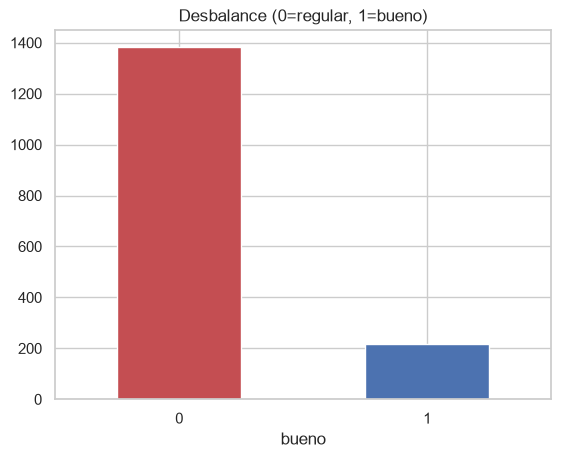

In [34]:
def cargar_wine_quality():
    for ruta in ["winequality-red.csv", "/content/winequality-red.csv"]:
        if os.path.exists(ruta):
            d = pd.read_csv(ruta, sep=";"); d.columns = [c.replace(" ", "_") for c in d.columns]; return d
    try:
        d = fetch_openml(name="wine-quality-red", version=1, as_frame=True, parser="auto").frame.copy()
    except Exception as e:
        raise FileNotFoundError("No se pudo descargar de OpenML. Sube 'winequality-red.csv' (sep=';') al panel de archivos de Colab.") from e
    if "quality" not in d.columns: d = d.rename(columns={"class": "quality"})
    for col in d.columns: d[col] = pd.to_numeric(d[col])
    return d

wq = cargar_wine_quality()
wq["bueno"] = (wq["quality"] >= 7).astype(int)
print(wq.shape); display(wq.head())
print("\nDistribución de calidad:\n", wq["quality"].value_counts().sort_index())
print("\nClases binarias:\n", wq["bueno"].value_counts(), "\n", wq["bueno"].value_counts(normalize=True).round(3))
wq["bueno"].value_counts().plot(kind="bar", rot=0, color=["#C44E52", "#4C72B0"], title="Desbalance (0=regular, 1=bueno)"); plt.show()

**Comentario sobre el desbalance:** solo ~13.6 % de los vinos son "buenos". Un modelo que prediga siempre "regular" tendría ~86 % de accuracy sin aprender nada, por eso se usa **F1** (clase positiva = bueno) en lugar de accuracy para comparar.

,mean,std
Reg. Logística,0.4155,0.0408
Árbol,0.4322,0.0686
SVM (RBF),0.3640,0.0899
KNN,0.4116,0.0585


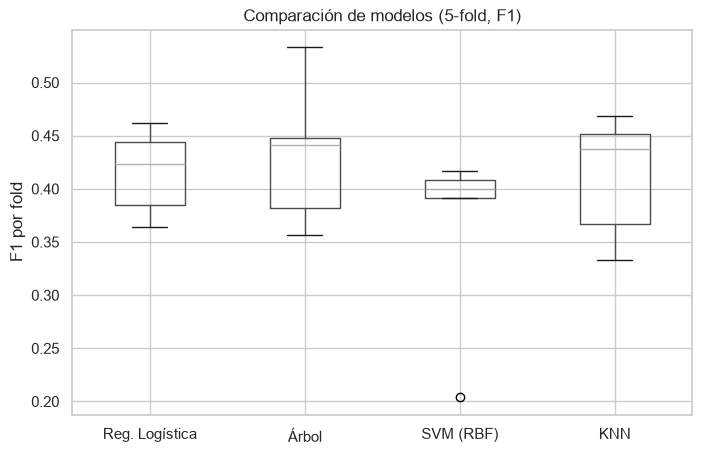

In [35]:
Xw = wq.drop(columns=["quality", "bueno"]); yw = wq["bueno"]
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.2, stratify=yw, random_state=RS)

pipes = {
    "Reg. Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Árbol": make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=RS)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC()),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
cv_f1 = {n: cross_val_score(p, Xw_tr, yw_tr, cv=cv, scoring="f1") for n, p in pipes.items()}
res = pd.DataFrame(cv_f1)
display(res.agg(["mean", "std"]).T.round(4))
res.boxplot(figsize=(8, 5)); plt.ylabel("F1 por fold"); plt.title("Comparación de modelos (5-fold, F1)"); plt.show()

Mejor modelo por F1 medio en CV: Árbol
              precision    recall  f1-score   support

     regular       0.95      0.94      0.95       277
       bueno       0.64      0.70      0.67        43

    accuracy                           0.91       320
   macro avg       0.80      0.82      0.81       320
weighted avg       0.91      0.91      0.91       320

Accuracy: 0.9062


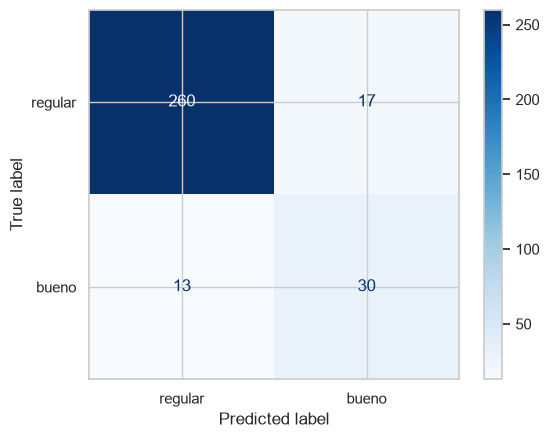

In [36]:
mejor = res.mean().idxmax(); print("Mejor modelo por F1 medio en CV:", mejor)
best = pipes[mejor].fit(Xw_tr, yw_tr); pred = best.predict(Xw_te)
print(classification_report(yw_te, pred, target_names=["regular", "bueno"]))
print("Accuracy:", round(accuracy_score(yw_te, pred), 4))
ConfusionMatrixDisplay.from_predictions(yw_te, pred, display_labels=["regular", "bueno"], cmap="Blues"); plt.show()

## Ejercicio 3.2 — GridSearchCV para optimizar SVM
`load_breast_cancer()`, pipeline `StandardScaler → SVC`.

In [37]:
Xtr, Xte, ytr, yte = train_test_split(bc.data, bc.target, test_size=0.3, stratify=bc.target, random_state=RS)
pipe = Pipeline([("scaler", StandardScaler()), ("svc", SVC())])
Cs = [0.01, 0.1, 1, 10, 100]; gammas = ["scale", 0.001, 0.01, 0.1, 1]
grid = [{"svc__kernel": ["linear"], "svc__C": Cs},
        {"svc__kernel": ["rbf"], "svc__C": Cs, "svc__gamma": gammas}]   # gamma solo aplica a RBF
gs = GridSearchCV(pipe, grid, cv=5, scoring="f1", n_jobs=-1).fit(Xtr, ytr)
print("Mejores hiperparámetros:", gs.best_params_); print("Mejor F1 (CV):", round(gs.best_score_, 4))

pred = gs.predict(Xte)
print("\nF1 test:", round(f1_score(yte, pred), 4), "| Accuracy test:", round(accuracy_score(yte, pred), 4))
print(classification_report(yte, pred, target_names=bc.target_names))

Mejores hiperparámetros: {'svc__C': 0.01, 'svc__kernel': 'linear'}
Mejor F1 (CV): 0.9843

F1 test: 0.968 | Accuracy test: 0.9591
              precision    recall  f1-score   support

   malignant       0.98      0.91      0.94        64
      benign       0.95      0.99      0.97       107

    accuracy                           0.96       171
   macro avg       0.96      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171



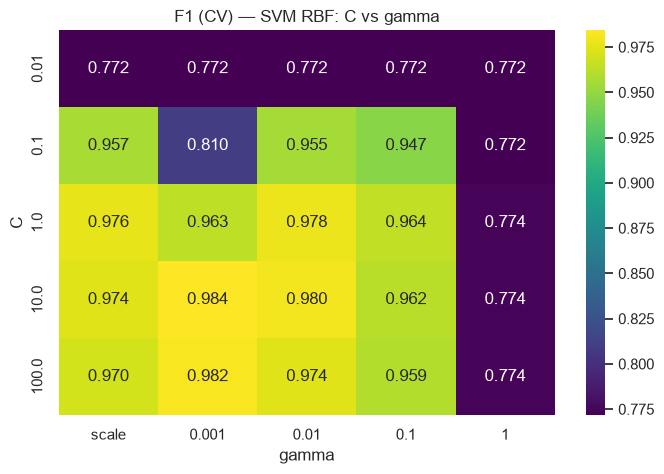

In [38]:
r = pd.DataFrame(gs.cv_results_); rbf = r[r["param_svc__kernel"] == "rbf"].copy()
rbf["C"] = rbf["param_svc__C"].astype(float); rbf["gamma"] = rbf["param_svc__gamma"].astype(str)
heat = rbf.pivot(index="C", columns="gamma", values="mean_test_score")[[str(g) for g in gammas]]
plt.figure(figsize=(8, 5)); sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis")
plt.title("F1 (CV) — SVM RBF: C vs gamma"); plt.show()

**Análisis 3.2** — En el heatmap RBF, `gamma` muy alto (fronteras muy locales → overfitting) o `C` muy bajo (regularización excesiva) degradan el F1; la zona buena está en `C` medio-alto con `gamma` pequeño/`scale`. En la ejecución de referencia el mejor modelo global fue el **kernel lineal** (F1 CV ≈ 0.98), lo que indica que Breast Cancer es casi linealmente separable: un modelo más simple rinde igual o mejor.

## Ejercicio 3.3 — Manejo de clases desbalanceadas
`make_classification` con 95 % / 5 %.

In [39]:
Xi, yi = make_classification(n_samples=1000, n_features=10, n_informative=4, n_redundant=2,
                             n_classes=2, weights=[0.95, 0.05], flip_y=0.01, class_sep=1.5, n_clusters_per_class=1, random_state=RS)
print("Distribución:", np.bincount(yi))
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, stratify=yi, random_state=RS)

def metricas(y, p):
    return {"Accuracy": accuracy_score(y, p), "Precision": precision_score(y, p, zero_division=0),
            "Recall": recall_score(y, p), "F1": f1_score(y, p)}

m_base = LogisticRegression(max_iter=1000).fit(Xi_tr, yi_tr)
m_bal = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xi_tr, yi_tr)
resultados = {"Sin balancear": metricas(yi_te, m_base.predict(Xi_te)),
              "class_weight='balanced'": metricas(yi_te, m_bal.predict(Xi_te))}
modelos_pr = {"Sin balancear": m_base, "class_weight='balanced'": m_bal}

Distribución: [942  58]


In [40]:
# SMOTE (imbalanced-learn). Se aplica SOLO sobre el train.
try:
    from imblearn.over_sampling import SMOTE
except ImportError:
    get_ipython().run_line_magic("pip", "install -q imbalanced-learn")
    from imblearn.over_sampling import SMOTE

Xs, ys = SMOTE(random_state=RS).fit_resample(Xi_tr, yi_tr)
print("Train tras SMOTE:", np.bincount(ys))
m_smote = LogisticRegression(max_iter=1000).fit(Xs, ys)
resultados["SMOTE"] = metricas(yi_te, m_smote.predict(Xi_te)); modelos_pr["SMOTE"] = m_smote
display(pd.DataFrame(resultados).T.round(3))


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Train tras SMOTE: [659 659]


,Accuracy,Precision,Recall,F1
Sin balancear,0.977,0.857,0.706,0.774
class_weight='balanced',0.913,0.390,0.941,0.552
SMOTE,0.927,0.429,0.882,0.577


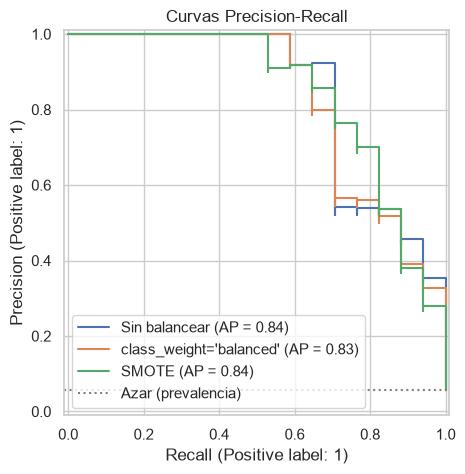

In [41]:
fig, ax = plt.subplots(figsize=(7, 5))
for n, m in modelos_pr.items(): PrecisionRecallDisplay.from_estimator(m, Xi_te, yi_te, ax=ax, name=n)
ax.axhline(yi_te.mean(), color="gray", ls=":", label="Azar (prevalencia)")
ax.set_title("Curvas Precision-Recall"); ax.legend(); plt.show()

**Respuestas 3.3** — La **accuracy es alta** (~95 %) incluso sin balancear porque predecir siempre la clase mayoritaria ya acierta el 95 % de las veces. El problema se revela en el **recall** (y F1) de la clase minoritaria, que es bajo. `class_weight='balanced'` y SMOTE elevan el recall a costa de algo de precisión (más falsos positivos); la curva Precision-Recall muestra el trade-off completo.

## Ejercicio 3.4 — Heart Disease: proyecto mini completo
**Restricción:** un falso negativo es más costoso que un falso positivo → priorizamos **recall** y **F2**.

In [42]:
def cargar_heart():
    df = None
    for ruta in ["heart.csv", "/content/heart.csv", "heart_disease.csv", "/content/heart_disease.csv"]:
        if os.path.exists(ruta): df = pd.read_csv(ruta); break
    if df is None:
        try: df = fetch_openml(name="heart-statlog", version=1, as_frame=True, parser="auto").frame.copy()
        except Exception as e:
            raise FileNotFoundError("No se pudo descargar. Sube 'heart.csv' (Kaggle: Heart Disease UCI) al panel de archivos de Colab.") from e
    t = next((t for t in ["target", "num", "class", "HeartDisease", "output", "condition"] if t in df.columns), None)
    if t is None: raise ValueError("No encuentro la columna objetivo; renómbrala a 'target'.")
    y = df[t]
    if str(y.dtype) in ("object", "category"): y = y.astype(str).str.lower().isin(["present", "yes", "1", "true"]).astype(int)
    else: y = (pd.to_numeric(y) > 0).astype(int)
    X = df.drop(columns=[t]).copy()
    for col in X.columns:
        if str(X[col].dtype) in ("object", "category"):
            conv = pd.to_numeric(X[col], errors="coerce")
            if conv.notna().sum() == X[col].notna().sum(): X[col] = conv
    return X, y

Xh, yh = cargar_heart()
print(Xh.shape); display(Xh.head()); display(Xh.describe().T.round(2))
print("\nValores faltantes:\n", Xh.isna().sum()[Xh.isna().sum() > 0])
print("\nTarget:\n", yh.value_counts(normalize=True).round(3))

(270, 13)


,age,sex,chest,resting_blood_pressure,serum_cholestoral,fasting_blood_sugar,resting_electrocardiographic_results,maximum_heart_rate_achieved,exercise_induced_angina,oldpeak,slope,number_of_major_vessels,thal
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3


,count,mean,std,min,25%,50%,75%,max
age,270.0,54.43,9.11,29.0,48.0,55.0,61.0,77.0
sex,270.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
chest,270.0,3.17,0.95,1.0,3.0,3.0,4.0,4.0
resting_blood_pressure,270.0,131.34,17.86,94.0,120.0,130.0,140.0,200.0
serum_cholestoral,270.0,249.66,51.69,126.0,213.0,245.0,280.0,564.0
fasting_blood_sugar,270.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
resting_electrocardiographic_results,270.0,1.02,1.00,0.0,0.0,2.0,2.0,2.0
maximum_heart_rate_achieved,270.0,149.68,23.17,71.0,133.0,153.5,166.0,202.0
exercise_induced_angina,270.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,270.0,1.05,1.15,0.0,0.0,0.8,1.6,6.2



Valores faltantes:
 Series([], dtype: int64)

Target:
 class
0    0.556
1    0.444
Name: proportion, dtype: float64


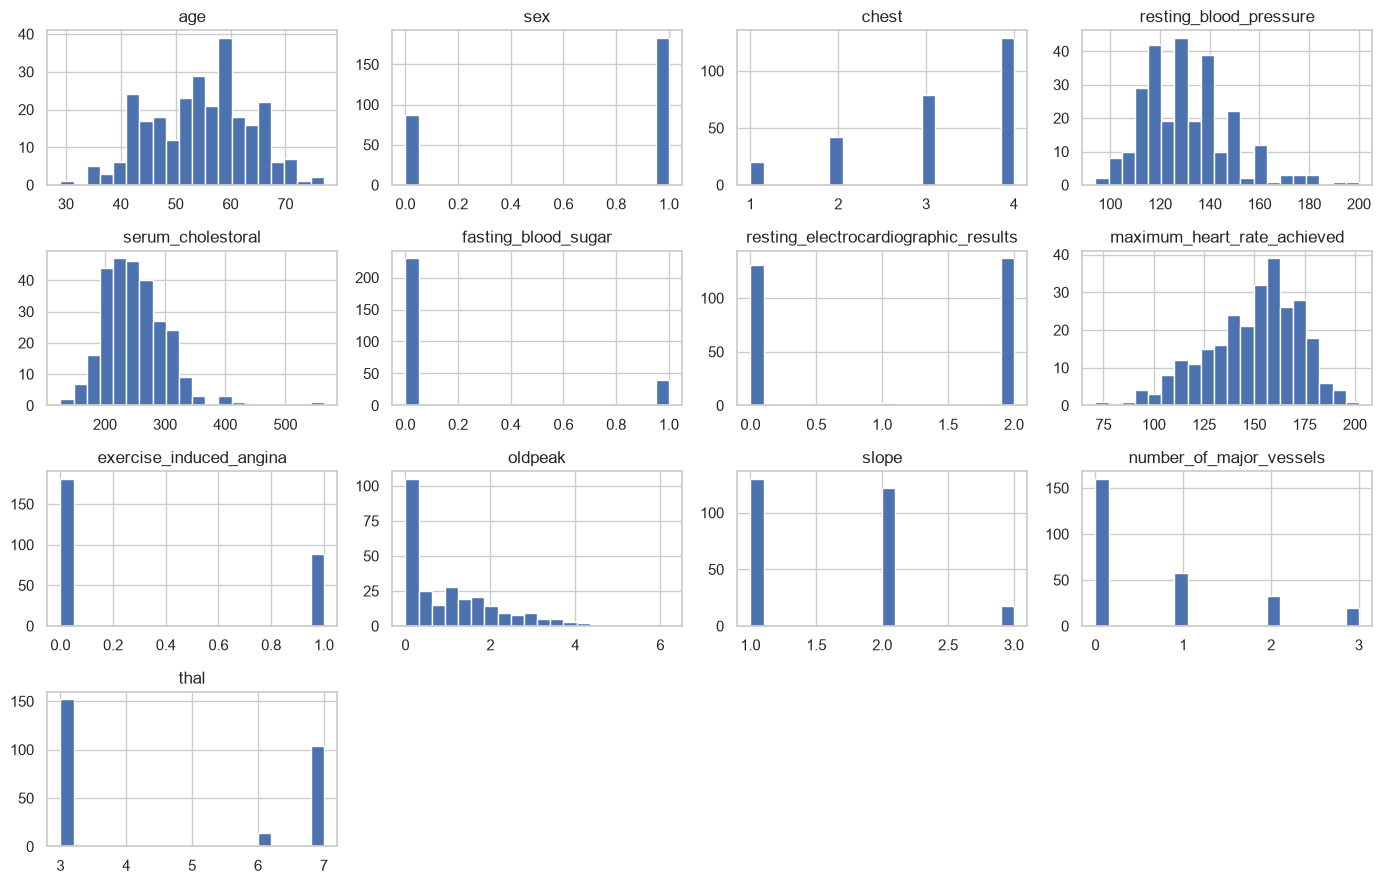

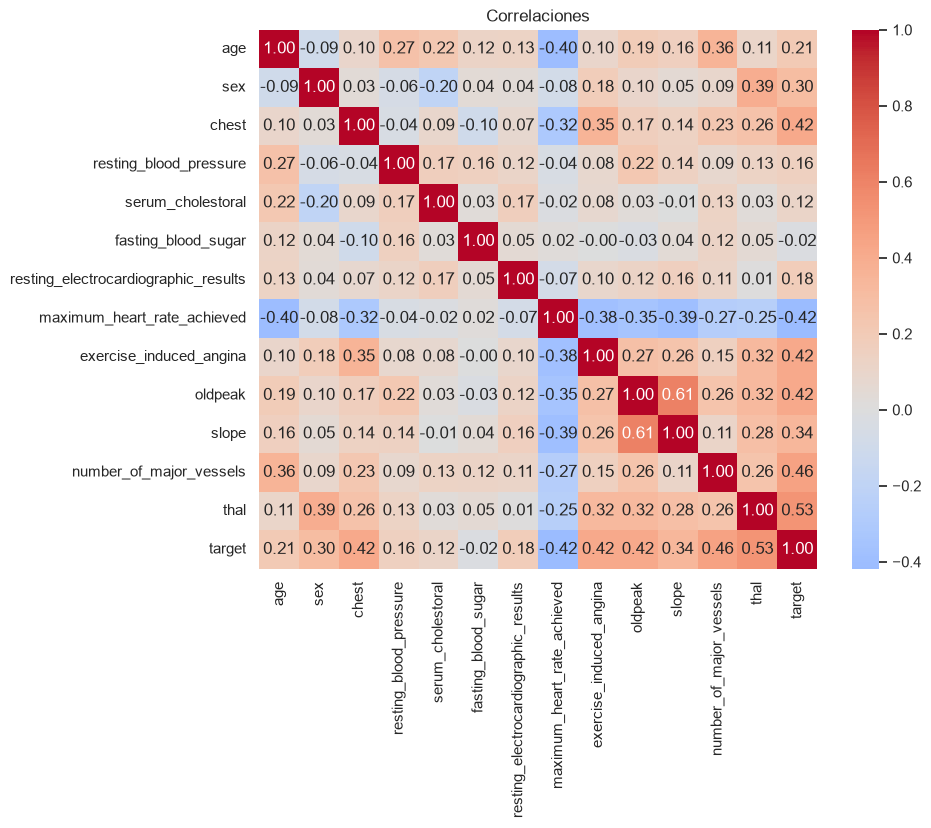

In [43]:
num_df = Xh.select_dtypes("number")
num_df.hist(figsize=(14, 9), bins=20); plt.tight_layout(); plt.show()
plt.figure(figsize=(9, 7)); sns.heatmap(pd.concat([num_df, yh.rename("target")], axis=1).corr(), cmap="coolwarm", center=0, annot=len(num_df.columns) < 16, fmt=".2f")
plt.title("Correlaciones"); plt.show()

In [44]:
# Preprocesamiento: columnas con pocos valores distintos o no numéricas -> categóricas (one-hot); el resto -> numéricas (mediana + escala)
cat_cols = [c for c in Xh.columns if Xh[c].nunique() <= 5 or not pd.api.types.is_numeric_dtype(Xh[c])]
num_cols = [c for c in Xh.columns if c not in cat_cols]
print("Numéricas:", num_cols); print("Categóricas:", cat_cols)

def make_prep():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(Xh, yh, test_size=0.2, stratify=yh, random_state=RS)
modelos = {
    "Reg. Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RS),
    "SVM (RBF)": SVC(probability=True, class_weight="balanced", random_state=RS)}
pipes_h = {n: Pipeline([("prep", make_prep()), ("model", m)]) for n, m in modelos.items()}

f2 = make_scorer(fbeta_score, beta=2)
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
filas = {}
for n, p in pipes_h.items():
    r = cross_validate(p, Xh_tr, yh_tr, cv=cv, scoring={"f1": "f1", "recall": "recall", "f2": f2, "roc_auc": "roc_auc"})
    filas[n] = {k.replace("test_", ""): v.mean() for k, v in r.items() if k.startswith("test_")}
res_h = pd.DataFrame(filas).T; display(res_h.round(3))

Numéricas: ['age', 'resting_blood_pressure', 'serum_cholestoral', 'maximum_heart_rate_achieved', 'oldpeak']
Categóricas: ['sex', 'chest', 'fasting_blood_sugar', 'resting_electrocardiographic_results', 'exercise_induced_angina', 'slope', 'number_of_major_vessels', 'thal']


,f1,recall,f2,roc_auc
Reg. Logística,0.819,0.844,0.833,0.910
Random Forest,0.772,0.791,0.783,0.899
SVM (RBF),0.810,0.823,0.817,0.903


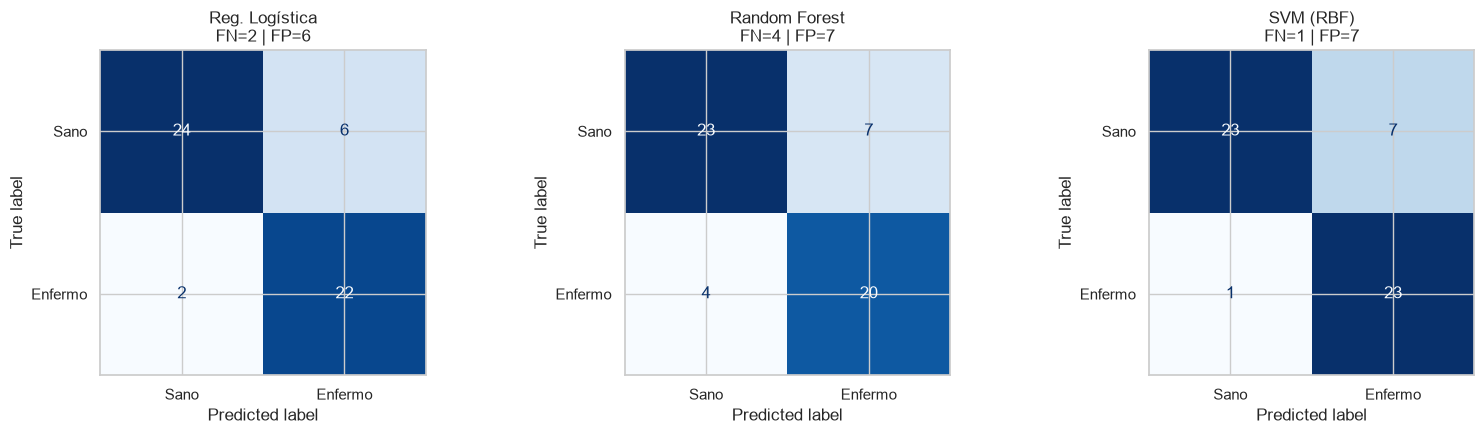

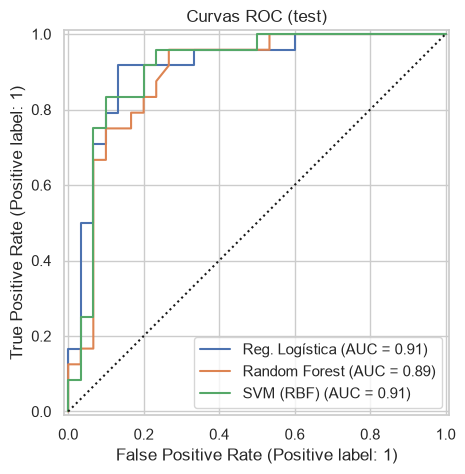

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (n, p) in zip(axes, pipes_h.items()):
    p.fit(Xh_tr, yh_tr); pr = p.predict(Xh_te)
    ConfusionMatrixDisplay.from_predictions(yh_te, pr, ax=ax, cmap="Blues", colorbar=False,
                                            display_labels=["Sano", "Enfermo"])
    ax.set_title(f"{n}\nFN={((yh_te==1)&(pr==0)).sum()} | FP={((yh_te==0)&(pr==1)).sum()}")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(6, 5))
for n, p in pipes_h.items(): RocCurveDisplay.from_estimator(p, Xh_te, yh_te, ax=ax, name=n)
ax.plot([0, 1], [0, 1], "k:"); ax.set_title("Curvas ROC (test)"); plt.show()

In [46]:
# Tuning del mejor modelo (según F2 en CV, que penaliza más los falsos negativos)
mejor_h = res_h["f2"].idxmax(); print("Modelo seleccionado para tuning:", mejor_h)
grids = {"Reg. Logística": {"model__C": [0.01, 0.1, 1, 10, 100]},
         "Random Forest": {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 3, 5]},
         "SVM (RBF)": {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01, 0.1]}}
gs_h = GridSearchCV(pipes_h[mejor_h], grids[mejor_h], cv=cv, scoring=f2, n_jobs=-1).fit(Xh_tr, yh_tr)
print("Mejores hiperparámetros:", gs_h.best_params_, "| F2 (CV):", round(gs_h.best_score_, 4))
modelo_final = gs_h.best_estimator_
pr = modelo_final.predict(Xh_te)
print(classification_report(yh_te, pr, target_names=["Sano", "Enfermo"]))
print("F2 test:", round(fbeta_score(yh_te, pr, beta=2), 4), "| ROC-AUC:", round(roc_auc_score(yh_te, modelo_final.predict_proba(Xh_te)[:, 1]), 4))

Modelo seleccionado para tuning: Reg. Logística
Mejores hiperparámetros: {'model__C': 1} | F2 (CV): 0.8327
              precision    recall  f1-score   support

        Sano       0.92      0.80      0.86        30
     Enfermo       0.79      0.92      0.85        24

    accuracy                           0.85        54
   macro avg       0.85      0.86      0.85        54
weighted avg       0.86      0.85      0.85        54

F2 test: 0.8871 | ROC-AUC: 0.9111


In [47]:
# Ajuste de umbral: bajar el umbral reduce falsos negativos (a costa de más falsos positivos)
proba_cv = cross_val_predict(modelo_final, Xh_tr, yh_tr, cv=cv, method="predict_proba")[:, 1]
umbrales = np.linspace(0.1, 0.9, 17)
tabla = pd.DataFrame([{"umbral": u, "recall": recall_score(yh_tr, proba_cv >= u),
                       "precision": precision_score(yh_tr, proba_cv >= u, zero_division=0)} for u in umbrales])
display(tabla.round(3).T)
cand = tabla[tabla.recall >= 0.90]
u_sel = cand.loc[cand.precision.idxmax(), "umbral"] if len(cand) else 0.5
pr_u = (modelo_final.predict_proba(Xh_te)[:, 1] >= u_sel).astype(int)
print(f"Umbral elegido (recall CV ≥ 0.90 con máxima precisión): {u_sel:.2f}")
print(f"Test -> recall={recall_score(yh_te, pr_u):.3f}  precision={precision_score(yh_te, pr_u):.3f}  FN={((yh_te==1)&(pr_u==0)).sum()}")

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
umbral,0.100,0.150,0.200,0.250,0.300,0.350,0.400,0.450,0.500,0.550,0.600,0.650,0.700,0.750,0.800,0.850,0.900
recall,0.948,0.938,0.917,0.906,0.906,0.896,0.885,0.854,0.844,0.771,0.760,0.750,0.719,0.708,0.677,0.583,0.521
precision,0.580,0.612,0.642,0.649,0.669,0.729,0.739,0.781,0.794,0.831,0.849,0.857,0.885,0.895,0.890,0.918,0.980


Umbral elegido (recall CV ≥ 0.90 con máxima precisión): 0.30
Test -> recall=0.958  precision=0.697  FN=1


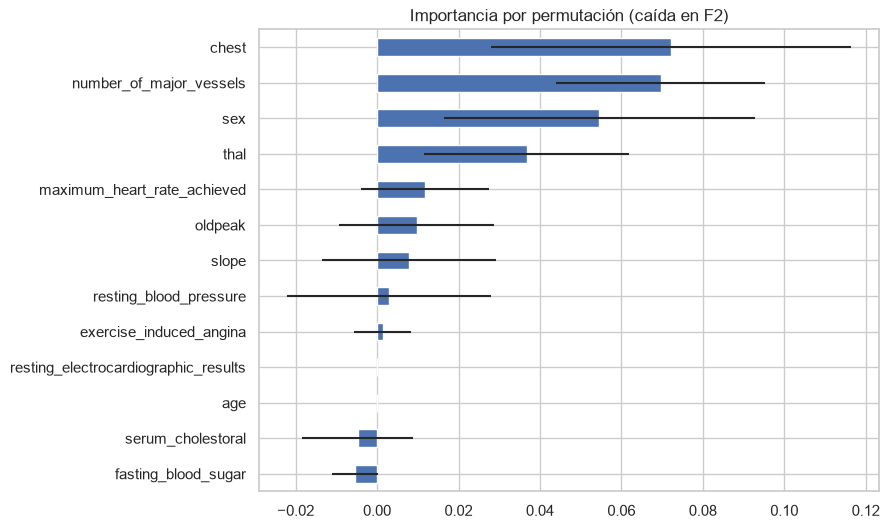

chest                          0.0721
number_of_major_vessels        0.0696
sex                            0.0546
thal                           0.0367
maximum_heart_rate_achieved    0.0118
dtype: float64


In [48]:
# Interpretación: importancia por permutación (sobre columnas originales)
pi = permutation_importance(modelo_final, Xh_te, yh_te, scoring=f2, n_repeats=20, random_state=RS)
imp = pd.Series(pi.importances_mean, index=Xh_te.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 6), xerr=pd.Series(pi.importances_std, index=Xh_te.columns)[imp.index], color="#4C72B0")
plt.title("Importancia por permutación (caída en F2)"); plt.show()
print(imp.sort_values(ascending=False).head(5).round(4))

**Justificación de la selección (3.4)** — Se eligió el modelo con mayor **F2/recall en CV** y se afinó con GridSearch sobre F2. Dado que un falso negativo (enfermo no detectado) es el error más grave, se priorizó el recall, y se ajustó el umbral de decisión para reducir FN aceptando más FP (que se resuelven con pruebas posteriores). Las features más importantes en este tipo de datos suelen ser **`thal`, `ca` (vasos principales), `cp` (tipo de dolor de pecho), `oldpeak`, `thalach`** (nombres según tu CSV); confirma con el gráfico.

---
# Nivel 4: Desafío
## Ejercicio 4.1 — Comparación justa de modelos con múltiples datasets

,Reg. Logística,Árbol,SVM (RBF),KNN
Iris,0.9532,0.9531,0.9599,0.9733
Wine,0.9833,0.8985,0.9833,0.9717
Breast Cancer,0.9734,0.9097,0.9771,0.9628
Digits,0.9710,0.8545,0.9839,0.9788


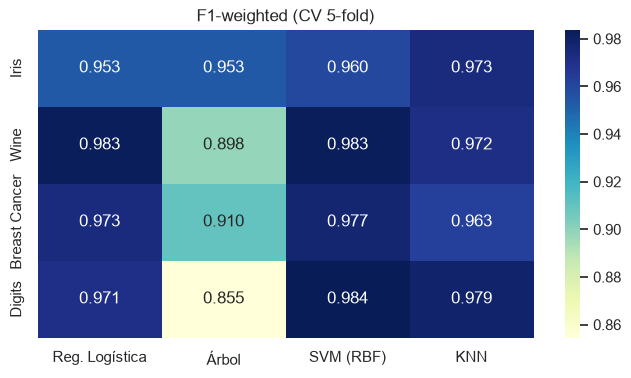

Mejor modelo por dataset:
 Iris                        KNN
Wine             Reg. Logística
Breast Cancer         SVM (RBF)
Digits                SVM (RBF)
dtype: str

Promedio por modelo:
 Reg. Logística    0.9703
Árbol             0.9039
SVM (RBF)         0.9760
KNN               0.9716
dtype: float64


In [49]:
datasets = {"Iris": load_iris(), "Wine": load_wine(), "Breast Cancer": load_breast_cancer(), "Digits": load_digits()}
modelos = {"Reg. Logística": LogisticRegression(max_iter=5000), "Árbol": DecisionTreeClassifier(random_state=RS),
           "SVM (RBF)": SVC(), "KNN": KNeighborsClassifier()}
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
medias, desv = {}, {}
for dn, d in datasets.items():
    medias[dn], desv[dn] = {}, {}
    for mn, m in modelos.items():
        s = cross_val_score(make_pipeline(StandardScaler(), clone(m)), d.data, d.target, cv=cv, scoring="f1_weighted", n_jobs=-1)
        medias[dn][mn], desv[dn][mn] = s.mean(), s.std()
tabla = pd.DataFrame(medias).T; display(tabla.round(4))
plt.figure(figsize=(8, 4)); sns.heatmap(tabla, annot=True, fmt=".3f", cmap="YlGnBu"); plt.title("F1-weighted (CV 5-fold)"); plt.show()
print("Mejor modelo por dataset:\n", tabla.idxmax(axis=1)); print("\nPromedio por modelo:\n", tabla.mean().round(4))

**Respuestas 4.1**

- **¿Hay un modelo "mejor" en todos?** No (*no free lunch*): las diferencias son pequeñas pero el ganador cambia. En la ejecución de referencia: **KNN en Iris, Reg. Logística en Wine, SVM-RBF en Breast Cancer y Digits**. Revisa `idxmax` de tu ejecución.
- **Qué favorece a cada modelo:** la **Reg. Logística** gana con datos casi linealmente separables y pocas muestras (Wine, Breast Cancer); **SVM-RBF/KNN** con fronteras no lineales y datos densos bien escalados (Digits); el **Árbol** suele ser el más débil y varianza alta, pero no requiere escalado y es interpretable.
- **Primera opción sin conocer el problema:** **SVM-RBF** (o Regresión Logística como línea base rápida e interpretable): rinde de forma consistente, con estandarización y un `C`/`gamma` razonable. Siempre conviene comparar contra una línea base simple.

## Ejercicio 4.2 — Impacto de features irrelevantes
Breast Cancer + 0…50 columnas de ruido gaussiano.

,SVM (RBF),KNN,Árbol
features de ruido,,,
0,0.9820,0.9712,0.9299
10,0.9751,0.9605,0.9394
20,0.9768,0.9545,0.9344
30,0.9767,0.9405,0.9294
40,0.9698,0.9404,0.9254
50,0.9659,0.9343,0.9211


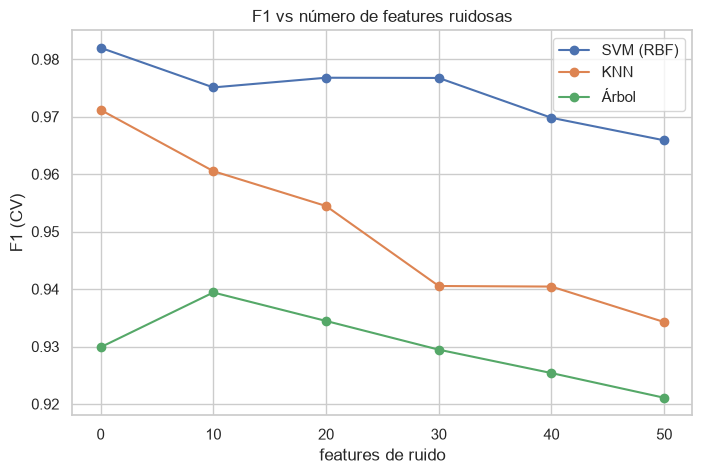

In [50]:
rng = np.random.RandomState(RS)
ruido = rng.randn(len(bc.data), 50)           # 50 columnas de ruido (las primeras k se usan en cada caso)
n_ruido = [0, 10, 20, 30, 40, 50]
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
modelos = {"SVM (RBF)": make_pipeline(StandardScaler(), SVC()),
           "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
           "Árbol": make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=RS))}
res = {n: [] for n in modelos}
for k in n_ruido:
    Xa = np.hstack([bc.data, ruido[:, :k]])
    for n, m in modelos.items(): res[n].append(cross_val_score(m, Xa, bc.target, cv=cv, scoring="f1").mean())
res_df = pd.DataFrame(res, index=n_ruido); res_df.index.name = "features de ruido"; display(res_df.round(4))
res_df.plot(marker="o", figsize=(8, 5)); plt.ylabel("F1 (CV)"); plt.title("F1 vs número de features ruidosas"); plt.show()

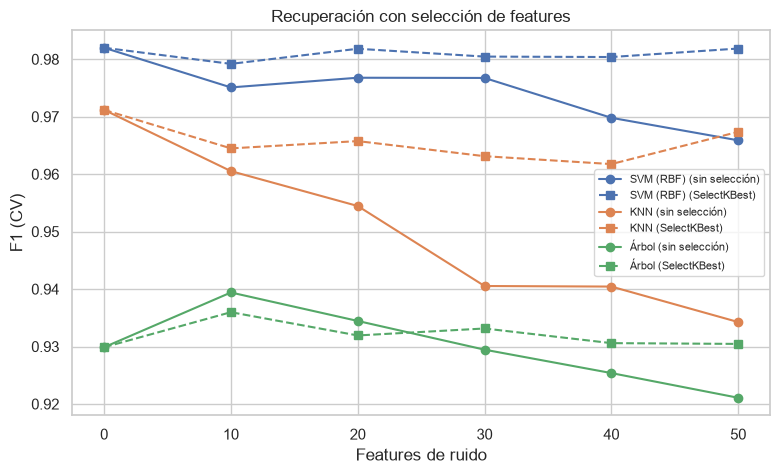

,SVM (RBF),KNN,Árbol
0,0.9820,0.9712,0.9299
10,0.9792,0.9645,0.9360
20,0.9818,0.9657,0.9319
30,0.9805,0.9631,0.9331
40,0.9804,0.9617,0.9306
50,0.9819,0.9674,0.9305


In [51]:
# Técnica de selección de features: SelectKBest(f_classif, k=30) DENTRO del pipeline (sin leakage)
sel = {"SVM (RBF)": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=30), SVC()),
       "KNN": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=30), KNeighborsClassifier()),
       "Árbol": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=30), DecisionTreeClassifier(random_state=RS))}
res_sel = {n: [] for n in sel}
for k in n_ruido:
    Xa = np.hstack([bc.data, ruido[:, :k]])
    for n, m in sel.items(): res_sel[n].append(cross_val_score(m, Xa, bc.target, cv=cv, scoring="f1").mean())
res_sel = pd.DataFrame(res_sel, index=n_ruido)
fig, ax = plt.subplots(figsize=(9, 5))
for i, n in enumerate(modelos):
    ax.plot(n_ruido, res_df[n], "o-", color=f"C{i}", label=f"{n} (sin selección)")
    ax.plot(n_ruido, res_sel[n], "s--", color=f"C{i}", label=f"{n} (SelectKBest)")
ax.set_xlabel("Features de ruido"); ax.set_ylabel("F1 (CV)"); ax.set_title("Recuperación con selección de features"); ax.legend(fontsize=8); plt.show()
display(res_sel.round(4))

**Respuestas 4.2** — **KNN** es el más sensible: cada feature irrelevante añade ruido a la distancia euclidiana (maldición de la dimensionalidad) y su F1 cae unos 4 puntos con 50 columnas de ruido (≈ 0.97 → 0.93). **SVM-RBF** también pierde (≈ 0.98 → 0.97) pero menos. El **Árbol** muestra la menor caída (≈ 0.93 → 0.92) porque elige, nodo a nodo, la feature más informativa y rara vez usa las de ruido, aunque parte de un F1 más bajo. **Solución:** selección de features (`SelectKBest` con ANOVA dentro del pipeline, sin leakage): al quedarse con las 30 mejores, SVM y KNN recuperan casi todo su rendimiento original.